# DATA 266 - Homework 8: Mini Diffusion Model (DDPM to DDIM)

**Objective.** Train a small DDPM-style diffusion model on MNIST and then change only the sampling procedure to get DDIM. The notebook shows how noise is added to an image (forward diffusion), how a CNN learns to predict that noise, and how the trained network is used to go from pure Gaussian noise back to digits with DDPM (100 steps) and DDIM (50 and 20 steps).

I started from `Demo_8_Diffusion.ipynb` and kept its schedule code, `q_sample`, `recover_x0_from_noise`, `TimeEmbedding`, and `denorm`. What I changed or added:

- **MNIST instead of FashionMNIST**, with the same [-1, 1] normalization as the demo.
- **Timestep labels.** The demo stores everything 0-indexed and adds 1 in the plot titles, so its "forward diffusion" figure never shows the clean image. Here the math uses t = 1, ..., T, t = 0 is the clean image, and the code converts with `t_idx = t - 1` (explained in Section 5).
- **A bigger denoiser.** The demo's `MiniDenoiser` has 3 conv layers and adds the time embedding once. Mine is a small conv encoder-decoder with the time embedding added in every block (Section 7).
- **Everything after the demo stopped:** the training loop, the loss plot, DDPM sampling, DDIM sampling, and the comparison.

## 2. Imports and Configuration

### Personal parameters

Same formulas as all the earlier assignments. The assert checks that the values match the ones I have used all semester.

- **SEED** seeds Python, NumPy, and PyTorch, the DataLoader shuffling, the noise for the forward-diffusion figure, the starting noise x_T, and the sampling noise.
- **SLICE** and **CLS_A** pick the image for the forward-diffusion figure: the first MNIST test image of digit CLS_A = 6 at index SLICE = 486 or later.
- **HP_ID** and **CLS_B** are only reported. The assignment fixes T, the beta schedule, the batch size, and the number of epochs, so there is no hyperparameter sweep.

In [1]:
SID4 = 9486
SEED = SID4
SLICE = SID4 % 1000
HP_ID = SID4 % 6
CLS_A = SID4 % 10
CLS_B = (CLS_A + 1 + ((SID4 // 10) % 9)) % 10

assert (SEED, SLICE, HP_ID, CLS_A, CLS_B) == (9486, 486, 0, 6, 0)

print(f"SID4  = {SID4}")
print(f"SEED  = {SEED}")
print(f"SLICE = {SLICE}")
print(f"HP_ID = {HP_ID}")
print(f"CLS_A = {CLS_A}")
print(f"CLS_B = {CLS_B}")

SID4  = 9486
SEED  = 9486
SLICE = 486
HP_ID = 0
CLS_A = 6
CLS_B = 0


In [2]:
import os
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")  # needed for deterministic cuBLAS on GPU

import json
import math
import random
import time
from datetime import datetime, timezone

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torchvision
from torch.utils.data import DataLoader, TensorDataset
from torchvision import datasets, transforms
from torchvision.utils import make_grid

plt.rcParams["figure.constrained_layout.use"] = True  # keeps suptitles from overlapping panel titles

### Experiment settings

The diffusion and training settings are the ones given in the assignment (T = 100, linear betas from 0.0001 to 0.02, batch size 128, 50 epochs).

**Smoke test vs. full run.** `SMOKE_TEST` is read from the environment variable `HW8_SMOKE_TEST`. It is off by default, so a normal "Run All" does the full experiment. With `HW8_SMOKE_TEST=1` the notebook trains for 1 epoch on 1,024 images and draws 16 samples per sampler. That is only for checking that every cell runs (shapes, training loop, samplers, figures). The smoke-test samples are not meant to look like digits.

In [3]:
SMOKE_TEST = os.environ.get("HW8_SMOKE_TEST", "0") == "1"

# diffusion (fixed by the assignment)
T = 100
BETA_START = 0.0001
BETA_END = 0.02

# training
BATCH_SIZE = 128
EPOCHS = 50
LR = 1e-3
BASE_CH = 32        # channels in the first block of the denoiser
TIME_DIM = 128      # size of the timestep embedding
TRAIN_SUBSET = None # None = all 60,000 training images

# sampling
N_SAMPLES = 64          # images per sampler (8 x 8 grid)
DDPM_STEPS = T          # DDPM always uses every step
DDIM_STEPS = [50, 20]
DDIM_ETA = 0.0          # 0 = deterministic DDIM

if SMOKE_TEST:
    EPOCHS = 1
    TRAIN_SUBSET = 1024
    N_SAMPLES = 16

print("SMOKE_TEST:", SMOKE_TEST)
print(f"T={T} | betas {BETA_START} -> {BETA_END} (linear) | batch {BATCH_SIZE} | epochs {EPOCHS} | lr {LR}")
print(f"samples per sampler {N_SAMPLES} | DDPM steps {DDPM_STEPS} | DDIM steps {DDIM_STEPS} | DDIM eta {DDIM_ETA}")

SMOKE_TEST: False
T=100 | betas 0.0001 -> 0.02 (linear) | batch 128 | epochs 50 | lr 0.001
samples per sampler 64 | DDPM steps 100 | DDIM steps [50, 20] | DDIM eta 0.0


## 3. Reproducibility and Device Setup

- `set_seed` seeds random, NumPy, and PyTorch. I call it again right before building the model and before training, so those cells do not depend on how many random numbers earlier cells used.
- `make_generator` gives a separate seeded `torch.Generator` for the DataLoader shuffle and for every piece of sampling noise. The sampling noise is drawn on the CPU and then moved to the device, so x_T is the same tensor on CUDA, MPS, or CPU.
- `torch.use_deterministic_algorithms(True, warn_only=True)` asks for deterministic kernels. I used `warn_only=True` so that if some op has no deterministic version on a backend, PyTorch prints a warning instead of stopping the run.
- The device is picked automatically: CUDA (the RTX 4090) first, then Apple MPS, then CPU. Setting `HW8_DEVICE=cpu` (or `mps`, `cuda`) overrides this.
- `log()` prints each line with a UTC timestamp and also writes it to `results/run_log_raw.txt`. All paths are relative to the notebook folder.

In [4]:
for folder in ["figures", "results", "checkpoints"]:
    os.makedirs(folder, exist_ok=True)

LOG_PATH = "results/run_log_raw.txt"
open(LOG_PATH, "w").close()  # start a fresh log for this run


def log(*args):
    stamp = datetime.now(timezone.utc).strftime("%Y-%m-%dT%H:%M:%SZ")
    line = f"[{stamp}] " + " ".join(str(a) for a in args)
    print(line)
    with open(LOG_PATH, "a") as f:
        f.write(line + "\n")


def set_seed(seed=SEED):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


def make_generator(seed=SEED):
    g = torch.Generator()
    g.manual_seed(seed)
    return g


def get_device():
    if torch.cuda.is_available():
        return "cuda"
    if torch.backends.mps.is_available():
        return "mps"
    return "cpu"


def sync():
    # wait for queued GPU work so that timings are real
    if device == "cuda":
        torch.cuda.synchronize()
    elif device == "mps":
        torch.mps.synchronize()


torch.use_deterministic_algorithms(True, warn_only=True)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
set_seed(SEED)

device = os.environ.get("HW8_DEVICE") or get_device()
device_name = torch.cuda.get_device_name(0) if device == "cuda" else ("Apple GPU (MPS)" if device == "mps" else "CPU only")
log("device:", device, "|", device_name, "| smoke test:", SMOKE_TEST)
log("torch", torch.__version__, "| torchvision", torchvision.__version__, "| numpy", np.__version__)

[2026-10-27T19:18:48Z] device: mps | Apple GPU (MPS) | smoke test: False
[2026-10-27T19:18:48Z] torch 2.14.0 | torchvision 0.29.0 | numpy 2.3.5


## 4. MNIST Data Loading

MNIST has 60,000 training and 10,000 test grayscale 28×28 digit images. I use the demo's transform: `ToTensor()` scales pixels to [0, 1] and `Normalize((0.5,), (0.5,))` maps them to [-1, 1]. Keeping the data centered at 0 matters here because the noise ε is also zero-mean with unit variance, so the clean image and the noise are on a similar scale.

Applying the transform image by image on every epoch is slow (PIL conversion for 60,000 images, 50 times). So I apply the same formula once to the whole uint8 tensor and wrap it in a `TensorDataset`. The assert checks that it gives exactly the same tensor as the transform pipeline. Labels are only used to pick the forward-diffusion image; the diffusion model itself is unconditional.

In [5]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,)),   # map [0, 1] -> [-1, 1]
])

t0 = time.time()
train_set = datasets.MNIST(root="data", train=True, download=True, transform=transform)
test_set = datasets.MNIST(root="data", train=False, download=True, transform=transform)


def to_tensor_dataset(ds):
    # same result as ToTensor + Normalize((0.5,), (0.5,)), but done once for the whole set
    x = ds.data.float().div(255).sub(0.5).div(0.5).unsqueeze(1)   # [N, 1, 28, 28] in [-1, 1]
    return TensorDataset(x, ds.targets.clone())


train_data = to_tensor_dataset(train_set)
test_data = to_tensor_dataset(test_set)
for i in [0, 1, SLICE]:
    assert torch.allclose(train_data[i][0], train_set[i][0], atol=1e-6)
    assert torch.allclose(test_data[i][0], test_set[i][0], atol=1e-6)

if TRAIN_SUBSET:
    train_data = TensorDataset(*train_data[:TRAIN_SUBSET])

train_loader = DataLoader(train_data, batch_size=BATCH_SIZE, shuffle=True, generator=make_generator(SEED))
log(f"MNIST ready in {time.time() - t0:.1f}s | train {len(train_data)} | test {len(test_data)} | batches per epoch {len(train_loader)}")

images, labels = next(iter(train_loader))
log(f"one batch: images {tuple(images.shape)}, labels {tuple(labels.shape)}, pixel range [{images.min().item():.3f}, {images.max().item():.3f}]")
assert images.shape == (BATCH_SIZE, 1, 28, 28) and images.min() >= -1 and images.max() <= 1

[2026-10-27T19:18:49Z] MNIST ready in 0.1s | train 60000 | test 10000 | batches per epoch 469
[2026-10-27T19:18:49Z] one batch: images (128, 1, 28, 28), labels (128,), pixel range [-1.000, 1.000]


The demo's `denorm` maps [-1, 1] back to [0, 1] for plotting. A few training images as a check:

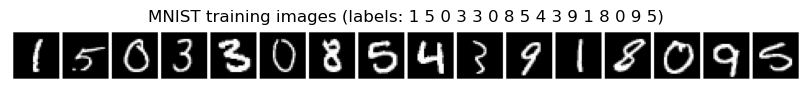

In [6]:
def denorm(x):
    return (x.clamp(-1, 1) + 1) / 2


def show_grid(ax, x, nrow, title):
    # x: [N, 1, 28, 28] in [-1, 1]
    grid = make_grid(denorm(x.detach().cpu()), nrow=nrow, padding=2, pad_value=1.0)
    ax.imshow(grid[0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(title)
    ax.axis("off")


fig, ax = plt.subplots(figsize=(8, 2.2))
show_grid(ax, images[:16], nrow=16, title="MNIST training images (labels: " + " ".join(str(int(l)) for l in labels[:16]) + ")")
plt.savefig("figures/mnist_examples.png", dpi=150)
plt.show()

## 5. Diffusion Schedule

Same linear schedule as the demo: T = 100 steps, with β_t going linearly from 0.0001 to 0.02.

$$\alpha_t = 1 - \beta_t, \qquad \bar{\alpha}_t = \prod_{i=1}^{t} \alpha_i$$

- **β_t** is the variance of the noise added at step t. It starts tiny, so the first steps barely change the image, and grows so that later steps remove more of the signal.
- **α_t** is how much of the signal one step keeps, and **ᾱ_t** is how much of the original image is left after t steps. √ᾱ_t multiplies the clean image and √(1 − ᾱ_t) multiplies the noise in the forward formula (Section 6).

**Timestep convention.** In the formulas t runs from 1 to T, and t = 0 means the clean image (ᾱ_0 = 1). Python arrays start at 0, so `betas[t - 1]` is β_t and the model gets `t_idx = t - 1` in [0, 99] (the same input the demo's `TimeEmbedding` gets). DDIM also needs ᾱ at t = 0, so I add `alpha_bars_full`, where `alpha_bars_full[t]` is ᾱ_t for t = 0, ..., T.

In [7]:
betas = torch.linspace(BETA_START, BETA_END, T, device=device)   # betas[t-1] = beta_t
alphas = 1.0 - betas
alpha_bars = torch.cumprod(alphas, dim=0)
sqrt_alpha_bars = torch.sqrt(alpha_bars)
sqrt_one_minus_alpha_bars = torch.sqrt(1.0 - alpha_bars)
alpha_bars_full = torch.cat([torch.ones(1, device=device), alpha_bars])   # alpha_bars_full[t] = alpha_bar_t, t = 0..T

assert betas.shape == alphas.shape == alpha_bars.shape == (T,)
assert alpha_bars_full.shape == (T + 1,) and alpha_bars_full[0] == 1

print(f"{'t':>4} {'beta_t':>9} {'alpha_bar_t':>12} {'sqrt(ab_t)':>11} {'sqrt(1-ab_t)':>13}")
for t in [1, 10, 30, 60, 100]:
    ab = alpha_bars_full[t].item()
    print(f"{t:>4} {betas[t - 1].item():>9.5f} {ab:>12.4f} {math.sqrt(ab):>11.4f} {math.sqrt(1 - ab):>13.4f}")

   t    beta_t  alpha_bar_t  sqrt(ab_t)  sqrt(1-ab_t)
   1   0.00010       0.9999      0.9999        0.0100
  10   0.00191       0.9900      0.9950        0.1000
  30   0.00593       0.9134      0.9557        0.2943
  60   0.01196       0.6954      0.8339        0.5519
 100   0.02000       0.3636      0.6030        0.7978


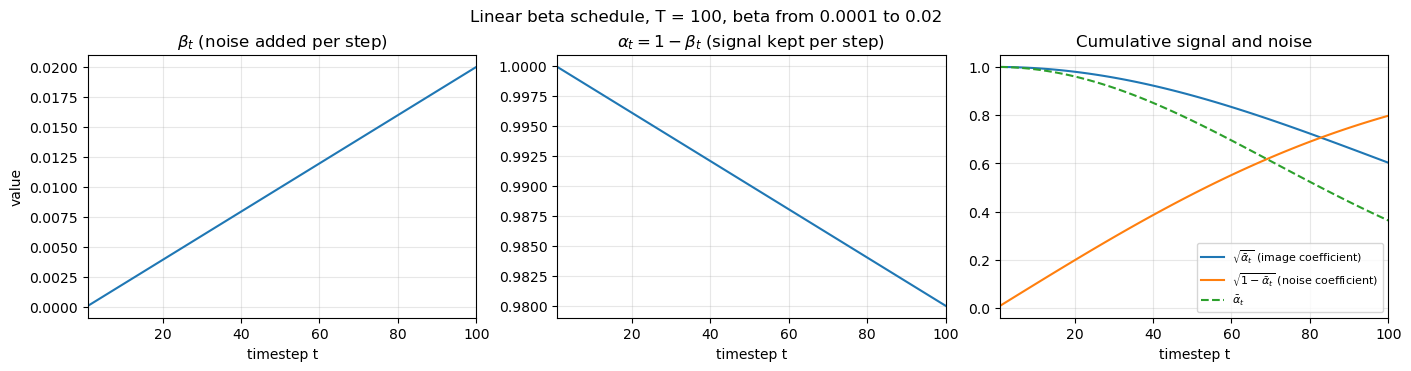

In [8]:
ts = np.arange(1, T + 1)
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))

axes[0].plot(ts, betas.cpu().numpy())
axes[0].set_title(r"$\beta_t$ (noise added per step)")

axes[1].plot(ts, alphas.cpu().numpy())
axes[1].set_title(r"$\alpha_t = 1 - \beta_t$ (signal kept per step)")

axes[2].plot(ts, sqrt_alpha_bars.cpu().numpy(), label=r"$\sqrt{\bar\alpha_t}$ (image coefficient)")
axes[2].plot(ts, sqrt_one_minus_alpha_bars.cpu().numpy(), label=r"$\sqrt{1-\bar\alpha_t}$ (noise coefficient)")
axes[2].plot(ts, alpha_bars.cpu().numpy(), "--", label=r"$\bar\alpha_t$")
axes[2].set_title("Cumulative signal and noise")
axes[2].legend(fontsize=8)

for ax in axes:
    ax.set_xlabel("timestep t")
    ax.set_xlim(1, T)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("value")
plt.suptitle(f"Linear beta schedule, T = {T}, beta from {BETA_START} to {BETA_END}")
plt.savefig("figures/beta_schedule.png", dpi=150)
plt.show()

One thing that stands out: with only 100 steps and β_T = 0.02, ᾱ_100 is about 0.36, so √ᾱ_100 ≈ 0.60. Even at the last step, x_100 still has about 60% of the original image in it. This schedule (with β_T = 0.02) comes from the DDPM paper, which used T = 1000, and there ᾱ_T is almost 0. With T = 100 the forward process never quite reaches pure noise. That matters for sampling, because the reverse process starts from pure N(0, I) noise, which is not exactly what the model saw at t = 100 during training. I keep the assignment's schedule and come back to this in the discussion.

## 6. Forward Diffusion

Adding noise one step at a time gives q(x_t | x_{t-1}) = N(√α_t x_{t-1}, β_t I). Because a sum of Gaussians is still Gaussian, the steps can be collapsed into one closed-form jump from the clean image to any t:

$$x_t = \sqrt{\bar{\alpha}_t}\, x_0 + \sqrt{1 - \bar{\alpha}_t}\, \epsilon, \qquad \epsilon \sim \mathcal{N}(0, I)$$

This is the demo's `q_sample`. It is what makes training cheap: for each image I can pick a random t and build x_t directly, without running t noising steps. `recover_x0_from_noise` is the same formula solved for x_0, which is what the samplers use later with the *predicted* noise.

In [9]:
def q_sample(x0, t, noise=None):
    '''
    Sample x_t directly from x_0 using the forward diffusion formula.

    Args:
        x0:    [B, 1, 28, 28] clean image batch
        t:     [B] integer timestep indices in [0, T-1] (t_idx = t - 1)
        noise: optional Gaussian noise of same shape as x0

    Returns:
        xt:    noisy image at timestep t
        noise: sampled Gaussian noise
    '''
    if noise is None:
        noise = torch.randn_like(x0)

    # .view(-1, 1, 1, 1) so the per-sample coefficient broadcasts over the image
    sqrt_ab = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    sqrt_1mab = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)

    xt = sqrt_ab * x0 + sqrt_1mab * noise
    return xt, noise


def recover_x0_from_noise(xt, t, eps):
    '''Recover x_0 from x_t if the noise eps is known (t is the 0-based index, like q_sample).'''
    sqrt_ab = sqrt_alpha_bars[t].view(-1, 1, 1, 1)
    sqrt_1mab = sqrt_one_minus_alpha_bars[t].view(-1, 1, 1, 1)
    return (xt - sqrt_1mab * eps) / sqrt_ab

For the figure I use one test image (the first digit 6 at index 486 or later) and **one fixed noise sample ε** for every timestep, so the only thing changing across the panels is the mix between the image and the noise. t = 0 is the clean image itself.

The cell also checks the formula three ways: the output shape, recovering x_0 exactly from x_t when the true ε is known, and the pixel statistics over a full test batch at t = 100 compared with what the formula predicts.

[2026-10-27T19:18:50Z] forward-diffusion image: test index 499, digit 6


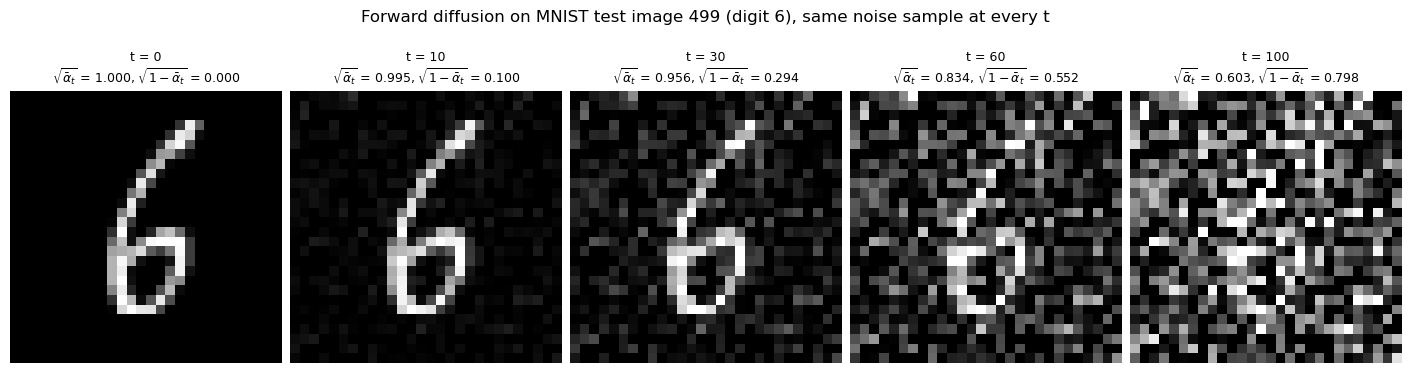

[2026-10-27T19:18:51Z] forward check: x_t shape (1, 1, 28, 28) | max |x0 - recovered x0| at t=60 = 1.19e-07
[2026-10-27T19:18:51Z] t=100 on 1000 test images: x_t mean -0.4571 (formula -0.4555) | std 0.8741 (formula 0.8752)


In [10]:
FWD_IDX = next(i for i in range(SLICE, len(test_data)) if int(test_data[i][1]) == CLS_A)
x0_img = test_data[FWD_IDX][0].unsqueeze(0).to(device)               # [1, 1, 28, 28]
eps_fixed = torch.randn(x0_img.shape, generator=make_generator(SEED)).to(device)
log(f"forward-diffusion image: test index {FWD_IDX}, digit {int(test_data[FWD_IDX][1])}")

FWD_TIMESTEPS = [0, 10, 30, 60, 100]
fig, axes = plt.subplots(1, len(FWD_TIMESTEPS), figsize=(14, 4.2))
for ax, t in zip(axes, FWD_TIMESTEPS):
    if t == 0:
        xt = x0_img
    else:
        xt, _ = q_sample(x0_img, torch.tensor([t - 1], device=device), eps_fixed)
    ab = alpha_bars_full[t].item()
    ax.imshow(denorm(xt[0, 0]).cpu(), cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"t = {t}\n" + rf"$\sqrt{{\bar\alpha_t}}$ = {math.sqrt(ab):.3f}, $\sqrt{{1-\bar\alpha_t}}$ = {math.sqrt(1 - ab):.3f}", fontsize=9)
    ax.axis("off")
plt.suptitle(f"Forward diffusion on MNIST test image {FWD_IDX} (digit {CLS_A}), same noise sample at every t")
plt.savefig("figures/forward_diffusion.png", dpi=150)
plt.show()

# check 1 and 2: shape, and exact recovery of x_0 when the true noise is known
t_check = torch.tensor([59], device=device)   # t = 60
xt_check, eps_check = q_sample(x0_img, t_check, eps_fixed)
x0_rec = recover_x0_from_noise(xt_check, t_check, eps_check)
rec_err = (x0_rec - x0_img).abs().max().item()
assert xt_check.shape == x0_img.shape and rec_err < 1e-4
log(f"forward check: x_t shape {tuple(xt_check.shape)} | max |x0 - recovered x0| at t=60 = {rec_err:.2e}")

# check 3: on a whole test batch at t = 100, mean/std of x_t should match the formula
xb = test_data[:1000][0].to(device)
xt_b, _ = q_sample(xb, torch.full((xb.size(0),), T - 1, device=device))
ab_T = alpha_bars[-1].item()
pred_mean = math.sqrt(ab_T) * xb.mean().item()
pred_std = math.sqrt(ab_T * xb.var().item() + (1 - ab_T))
log(f"t=100 on 1000 test images: x_t mean {xt_b.mean().item():.4f} (formula {pred_mean:.4f}) | std {xt_b.std().item():.4f} (formula {pred_std:.4f})")

## 7. CNN Noise-Prediction Model

The network ε_θ(x_t, t) takes a noisy image and its timestep and outputs a tensor with the same shape as the image, [B, 1, 28, 28], which is its guess for the noise ε that was added.

**Timestep conditioning.** The same network has to denoise at every t, and how much noise there is depends on t (at t = 10 the image is almost clean, at t = 100 it is mostly noise), so the model has to be told t. I do it in three steps:

1. **Sinusoidal embedding** (the demo's `TimeEmbedding`): the integer t_idx becomes a 128-dimensional vector of sin(t·ω_k) and cos(t·ω_k) at many frequencies ω_k, like positional encodings in transformers. Nearby timesteps get similar vectors, which is easier for the network to use than a raw integer.
2. **A small MLP** (Linear → ReLU → Linear) turns that into a learned 128-dimensional time feature.
3. **Injection in every block:** each `ConvBlock` has its own `Linear(128, channels)` that maps the time feature to one value per channel. This value is added to the feature map after the block's first convolution, broadcast over all 28×28 (or 14×14, 7×7) positions. In other words, t shifts each channel up or down, so the same filters can act differently at different noise levels.

The demo adds the time embedding only once, before its last conv. Adding it in every block means every layer knows the noise level.

**Architecture.** A small encoder-decoder (U-Net style) with skip connections:

| Part | Layers | Output shape |
| --- | --- | --- |
| `enc1` | ConvBlock(1 → 32) | [B, 32, 28, 28] |
| `down1` | Conv 3×3, stride 2 | [B, 32, 14, 14] |
| `enc2` | ConvBlock(32 → 64) | [B, 64, 14, 14] |
| `down2` | Conv 3×3, stride 2 | [B, 64, 7, 7] |
| `mid` | ConvBlock(64 → 128) | [B, 128, 7, 7] |
| `up2` + `dec2` | ConvTranspose 4×4 stride 2, concat with `enc2`, ConvBlock(128 → 64) | [B, 64, 14, 14] |
| `up1` + `dec1` | ConvTranspose 4×4 stride 2, concat with `enc1`, ConvBlock(64 → 32) | [B, 32, 28, 28] |
| `out` | Conv 1×1 (32 → 1), no activation | [B, 1, 28, 28] |

Each ConvBlock is Conv 3×3 → GroupNorm → ReLU → (+ time) → Conv 3×3 → GroupNorm → ReLU. That gives 15 convolution layers in total, with ReLU as the nonlinearity. Downsampling lets the 3×3 filters see the whole digit at 7×7, and the skip connections carry the fine 28×28 detail straight to the output. The last layer has no activation because the noise can be any real number. I used strided and transposed convolutions instead of pooling and `Upsample` because they have deterministic GPU kernels.

In [11]:
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.dim = dim

    def forward(self, t):
        '''
        Sinusoidal timestep embedding

        Args:
            t: [B]

        Returns:
            emb: [B, dim]
        '''
        half = self.dim // 2
        freqs = torch.exp(
            -math.log(10000) * torch.arange(0, half, device=t.device).float() / half
        )
        angles = t.float().unsqueeze(1) * freqs.unsqueeze(0)
        emb = torch.cat([torch.sin(angles), torch.cos(angles)], dim=1)
        return emb


class ConvBlock(nn.Module):
    '''Two 3x3 convs with GroupNorm + ReLU. The time embedding is added after the first conv.'''

    def __init__(self, in_ch, out_ch, time_dim):
        super().__init__()
        self.conv1 = nn.Conv2d(in_ch, out_ch, kernel_size=3, padding=1)
        self.norm1 = nn.GroupNorm(8, out_ch)
        self.time_proj = nn.Linear(time_dim, out_ch)
        self.conv2 = nn.Conv2d(out_ch, out_ch, kernel_size=3, padding=1)
        self.norm2 = nn.GroupNorm(8, out_ch)
        self.act = nn.ReLU()

    def forward(self, x, temb):
        h = self.act(self.norm1(self.conv1(x)))
        h = h + self.time_proj(temb)[:, :, None, None]   # [B, C] -> [B, C, 1, 1], same shift at every pixel
        h = self.act(self.norm2(self.conv2(h)))
        return h


class MiniDenoiser(nn.Module):
    def __init__(self, base_ch=32, time_dim=128):
        super().__init__()
        c = base_ch
        self.time_mlp = nn.Sequential(
            TimeEmbedding(time_dim),
            nn.Linear(time_dim, time_dim),
            nn.ReLU(),
            nn.Linear(time_dim, time_dim),
        )
        self.enc1 = ConvBlock(1, c, time_dim)                                   # 28x28
        self.down1 = nn.Conv2d(c, c, kernel_size=3, stride=2, padding=1)        # -> 14x14
        self.enc2 = ConvBlock(c, 2 * c, time_dim)
        self.down2 = nn.Conv2d(2 * c, 2 * c, kernel_size=3, stride=2, padding=1)  # -> 7x7
        self.mid = ConvBlock(2 * c, 4 * c, time_dim)
        self.up2 = nn.ConvTranspose2d(4 * c, 2 * c, kernel_size=4, stride=2, padding=1)  # -> 14x14
        self.dec2 = ConvBlock(4 * c, 2 * c, time_dim)                           # input: up2 + enc2 skip
        self.up1 = nn.ConvTranspose2d(2 * c, c, kernel_size=4, stride=2, padding=1)      # -> 28x28
        self.dec1 = ConvBlock(2 * c, c, time_dim)                               # input: up1 + enc1 skip
        self.out = nn.Conv2d(c, 1, kernel_size=1)

    def forward(self, x, t):
        '''
        Args:
            x: [B, 1, 28, 28] noisy images x_t
            t: [B] timestep indices (t_idx = t - 1)

        Returns:
            predicted noise: [B, 1, 28, 28]
        '''
        temb = self.time_mlp(t)
        h1 = self.enc1(x, temb)
        h2 = self.enc2(self.down1(h1), temb)
        h = self.mid(self.down2(h2), temb)
        h = self.dec2(torch.cat([self.up2(h), h2], dim=1), temb)
        h = self.dec1(torch.cat([self.up1(h), h1], dim=1), temb)
        return self.out(h)

Checks before training: the output shape must equal the input shape, the model must have at least four conv layers, and the output must actually change when only t changes (otherwise the conditioning would not be doing anything).

In [12]:
set_seed(SEED)
model = MiniDenoiser(base_ch=BASE_CH, time_dim=TIME_DIM).to(device)
print(model)

n_params = sum(p.numel() for p in model.parameters())
n_conv = sum(isinstance(m, (nn.Conv2d, nn.ConvTranspose2d)) for m in model.modules())
log(f"MiniDenoiser parameters: {n_params:,} | conv layers: {n_conv}")

with torch.no_grad():
    x_chk = images[:8].to(device)
    t_chk = torch.randint(0, T, (8,), device=device)
    out_chk = model(x_chk, t_chk)
    out_t0 = model(x_chk, torch.zeros(8, dtype=torch.long, device=device))
    out_t99 = model(x_chk, torch.full((8,), T - 1, device=device))
t_effect = (out_t0 - out_t99).abs().mean().item()
log(f"shape check: input {tuple(x_chk.shape)}, t {tuple(t_chk.shape)} -> predicted noise {tuple(out_chk.shape)}")
log(f"conditioning check: mean |eps_theta(x, t=1) - eps_theta(x, t=100)| = {t_effect:.4f} (untrained model)")
assert out_chk.shape == x_chk.shape
assert n_conv >= 4
assert t_effect > 0

MiniDenoiser(
  (time_mlp): Sequential(
    (0): TimeEmbedding()
    (1): Linear(in_features=128, out_features=128, bias=True)
    (2): ReLU()
    (3): Linear(in_features=128, out_features=128, bias=True)
  )
  (enc1): ConvBlock(
    (conv1): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (time_proj): Linear(in_features=128, out_features=32, bias=True)
    (conv2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm2): GroupNorm(8, 32, eps=1e-05, affine=True, bias=True)
    (act): ReLU()
  )
  (down1): Conv2d(32, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
  (enc2): ConvBlock(
    (conv1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (norm1): GroupNorm(8, 64, eps=1e-05, affine=True, bias=True)
    (time_proj): Linear(in_features=128, out_features=64, bias=True)
    (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  

## 8. Training

Each training step follows the DDPM training algorithm:

1. take a batch of clean images x_0,
2. pick a random timestep for each image, t ~ Uniform{1, ..., T},
3. sample ε ~ N(0, I) and build x_t with `q_sample`,
4. predict the noise and minimize

$$L = \text{MSE}\big(\epsilon, \epsilon_\theta(x_t, t)\big) = \mathbb{E}\,\big\|\epsilon - \epsilon_\theta(x_t, t)\big\|^2$$

Because t is random, one batch trains the model on many noise levels at once.

**Settings:** Adam with learning rate 1e-3, decayed to 0 with a cosine schedule over all training steps (a smaller learning rate near the end gives smoother final weights, which helps sample quality), batch size 128, 50 epochs. I record the loss of every batch and the mean per epoch.

To get a held-out number, `eval_mse` computes the same loss on the 10,000 test images with a fixed seed for t and ε, so the value is comparable before and after training. It is not used for any training decision.

In [13]:
@torch.no_grad()
def eval_mse(model, data, seed=SEED, batch_size=500):
    # noise-prediction MSE on a dataset, with fixed (seeded) timesteps and noise
    model.eval()
    g = make_generator(seed)
    total, count = 0.0, 0
    for x0, _ in DataLoader(data, batch_size=batch_size, shuffle=False):
        t_idx = torch.randint(0, T, (x0.size(0),), generator=g)
        eps = torch.randn(x0.shape, generator=g)
        x0, t_idx, eps = x0.to(device), t_idx.to(device), eps.to(device)
        xt, _ = q_sample(x0, t_idx, eps)
        total += nn.functional.mse_loss(model(xt, t_idx), eps, reduction="sum").item()
        count += eps.numel()
    return total / count


test_mse_before = eval_mse(model, test_data)
log(f"test noise-prediction MSE before training: {test_mse_before:.5f}")

[2026-10-27T19:18:59Z] test noise-prediction MSE before training: 1.28678


In [14]:
set_seed(SEED)
optimizer = torch.optim.Adam(model.parameters(), lr=LR)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS * len(train_loader))
loss_fn = nn.MSELoss()

step_losses, epoch_losses = [], []
train_start = time.time()
for epoch in range(1, EPOCHS + 1):
    model.train()
    epoch_start = time.time()
    for x0, _ in train_loader:
        x0 = x0.to(device)
        t_idx = torch.randint(0, T, (x0.size(0),), device=device)   # random timestep per image
        xt, eps = q_sample(x0, t_idx)
        loss = loss_fn(model(xt, t_idx), eps)

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()
        scheduler.step()
        step_losses.append(loss.item())

    epoch_losses.append(float(np.mean(step_losses[-len(train_loader):])))
    log(f"[epoch {epoch:02d}/{EPOCHS}] train MSE {epoch_losses[-1]:.5f} | lr {scheduler.get_last_lr()[0]:.2e} | {time.time() - epoch_start:.1f}s")

train_time = time.time() - train_start
test_mse_after = eval_mse(model, test_data)
log(f"training done in {train_time:.1f}s ({train_time / 60:.1f} min) | {len(step_losses)} steps")
log(f"test noise-prediction MSE: before {test_mse_before:.5f} -> after {test_mse_after:.5f}")

torch.save(model.state_dict(), f"checkpoints/mini_ddpm_seed_{SEED}.pt")

[2026-10-27T19:21:03Z] [epoch 01/50] train MSE 0.12903 | lr 9.99e-04 | 124.1s


[2026-10-27T19:23:13Z] [epoch 02/50] train MSE 0.07834 | lr 9.96e-04 | 129.8s


[2026-10-27T19:25:16Z] [epoch 03/50] train MSE 0.06923 | lr 9.91e-04 | 123.7s


[2026-10-27T19:27:18Z] [epoch 04/50] train MSE 0.06564 | lr 9.84e-04 | 121.8s


[2026-10-27T19:29:22Z] [epoch 05/50] train MSE 0.06317 | lr 9.76e-04 | 123.9s


...

[2026-10-27T20:50:08Z] [epoch 47/50] train MSE 0.05255 | lr 8.86e-06 | 119.8s


[2026-10-27T20:52:06Z] [epoch 48/50] train MSE 0.05244 | lr 3.94e-06 | 117.8s


[2026-10-27T20:54:02Z] [epoch 49/50] train MSE 0.05248 | lr 9.87e-07 | 115.7s


[2026-10-27T20:55:57Z] [epoch 50/50] train MSE 0.05244 | lr 0.00e+00 | 115.1s


[2026-10-27T20:56:03Z] training done in 5817.9s (97.0 min) | 23450 steps
[2026-10-27T20:56:03Z] test noise-prediction MSE: before 1.28678 -> after 0.05245


## 9. Training-Loss Visualization

Left: the loss of every batch (light line) and a moving average over 100 batches (one epoch is 469 batches). Right: the mean training loss of each epoch. Both use a log scale, because the loss drops a lot in the first epoch and then keeps decreasing slowly. The per-batch loss stays noisy even late in training because every batch has a different random mix of timesteps, and how hard it is to predict the noise depends on t.

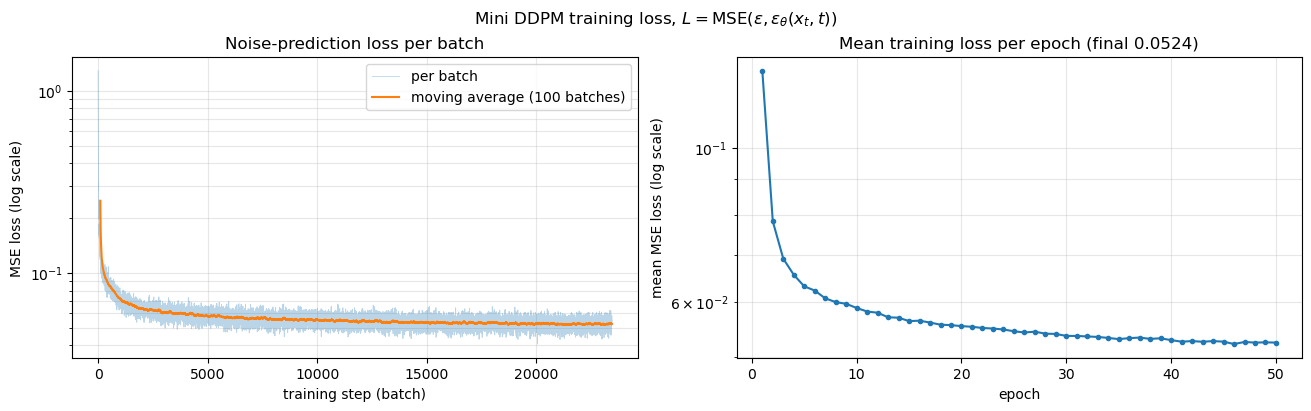

[2026-10-27T20:56:04Z] epoch losses: first 0.12903 | last 0.05244 | min 0.05219 (epoch 46)


In [15]:
window = min(100, len(step_losses))
moving_avg = np.convolve(step_losses, np.ones(window) / window, mode="valid")

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(step_losses, alpha=0.3, linewidth=0.6, label="per batch")
axes[0].plot(np.arange(window - 1, len(step_losses)), moving_avg, linewidth=1.5, label=f"moving average ({window} batches)")
axes[0].set_xlabel("training step (batch)")
axes[0].set_ylabel("MSE loss (log scale)")
axes[0].set_yscale("log")
axes[0].set_title("Noise-prediction loss per batch")
axes[0].legend()
axes[0].grid(alpha=0.3, which="both")

axes[1].plot(range(1, EPOCHS + 1), epoch_losses, marker="o", markersize=3)
axes[1].set_xlabel("epoch")
axes[1].set_ylabel("mean MSE loss (log scale)")
axes[1].set_yscale("log")
axes[1].set_title(f"Mean training loss per epoch (final {epoch_losses[-1]:.4f})")
axes[1].grid(alpha=0.3, which="both")

plt.suptitle(r"Mini DDPM training loss, $L = \mathrm{MSE}(\epsilon, \epsilon_\theta(x_t, t))$")
plt.savefig("figures/training_loss.png", dpi=150)
plt.show()

log(f"epoch losses: first {epoch_losses[0]:.5f} | last {epoch_losses[-1]:.5f} | min {min(epoch_losses):.5f} (epoch {int(np.argmin(epoch_losses)) + 1})")

## 10. DDPM Sampling

To generate images, DDPM runs the chain backwards, one step at a time, starting from pure noise x_T ~ N(0, I). For t = T, ..., 1:

$$x_{t-1} = \frac{1}{\sqrt{\alpha_t}}\left(x_t - \frac{\beta_t}{\sqrt{1 - \bar{\alpha}_t}}\, \epsilon_\theta(x_t, t)\right) + \sigma_t z, \qquad z \sim \mathcal{N}(0, I)$$

- The first term is the model's estimate of the mean of x_{t-1}. It removes the small part of the predicted noise that belongs to step t, then rescales by 1/√α_t to undo the √α_t shrinking from the forward step.
- σ_t z adds fresh random noise. I use σ_t² = β_t, one of the two choices in the DDPM paper. No noise is added at the last step (t = 1), so the final output is the clean estimate.

Each step only moves from t to t − 1, so generating one image takes **100 network calls**, and since new noise is drawn at every step, the same x_T gives a different image each time.

All three samplers in this notebook start from **the same x_T** (64 noise images drawn with SEED), so the results can be compared image by image in Section 12. `save_at` keeps some intermediate x_t values so the reverse process can be plotted.

In [16]:
@torch.no_grad()
def ddpm_sample(model, x_T, generator, save_at=()):
    '''
    DDPM reverse process, t = T, ..., 1.
    generator: seeded CPU generator for the noise z added at each step
    save_at:   timesteps whose x_t should be kept (for plotting)
    '''
    model.eval()
    x = x_T.clone()
    traj = {T: x.cpu()} if T in save_at else {}
    for t in range(T, 0, -1):
        i = t - 1                                       # array index of step t
        t_batch = torch.full((x.size(0),), i, device=device, dtype=torch.long)
        eps_hat = model(x, t_batch)
        mean = (x - betas[i] / sqrt_one_minus_alpha_bars[i] * eps_hat) / torch.sqrt(alphas[i])
        if t > 1:
            z = torch.randn(x.shape, generator=generator).to(device)
            x = mean + torch.sqrt(betas[i]) * z         # sigma_t^2 = beta_t
        else:
            x = mean                                    # no noise at the last step
        if t - 1 in save_at:
            traj[t - 1] = x.cpu()
    return x, traj


TRAJ_STEPS = [100, 80, 60, 40, 20, 0]
x_T = torch.randn((N_SAMPLES, 1, 28, 28), generator=make_generator(SEED)).to(device)
log(f"starting noise x_T: shape {tuple(x_T.shape)}, mean {x_T.mean().item():.4f}, std {x_T.std().item():.4f}")

# one warm-up call so the first timing does not include one-time GPU setup
with torch.no_grad():
    model.eval()
    model(x_T, torch.zeros(N_SAMPLES, dtype=torch.long, device=device))

sync(); t0 = time.time()
ddpm_imgs, ddpm_traj = ddpm_sample(model, x_T, generator=make_generator(SEED + 1), save_at=TRAJ_STEPS)
sync(); ddpm_time = time.time() - t0

assert ddpm_imgs.shape == x_T.shape and torch.isfinite(ddpm_imgs).all()
log(f"DDPM {DDPM_STEPS} steps: {N_SAMPLES} images in {ddpm_time:.2f}s | output range [{ddpm_imgs.min().item():.2f}, {ddpm_imgs.max().item():.2f}]")

[2026-10-27T20:56:04Z] starting noise x_T: shape (64, 1, 28, 28), mean -0.0017, std 1.0007


[2026-10-27T20:56:08Z] DDPM 100 steps: 64 images in 3.56s | output range [-1.04, 1.04]


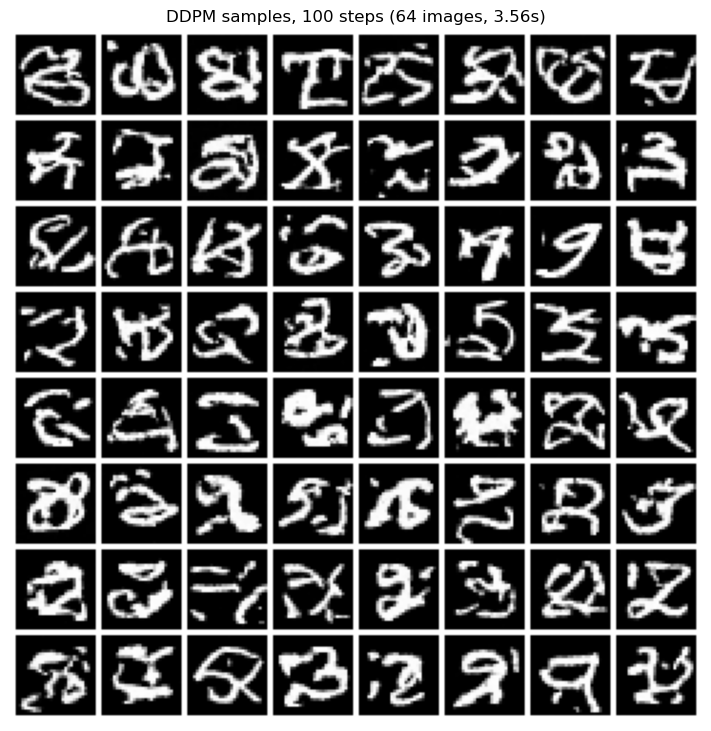

In [17]:
nrow = int(math.sqrt(N_SAMPLES))
fig, ax = plt.subplots(figsize=(7, 7.4))
show_grid(ax, ddpm_imgs, nrow=nrow, title=f"DDPM samples, {DDPM_STEPS} steps ({N_SAMPLES} images, {ddpm_time:.2f}s)")
plt.savefig("figures/ddpm_samples.png", dpi=150)
plt.show()

The reverse process for the first 6 samples. Each row is one sample, each column is x_t at the timestep shown (t = 0 is the final output).

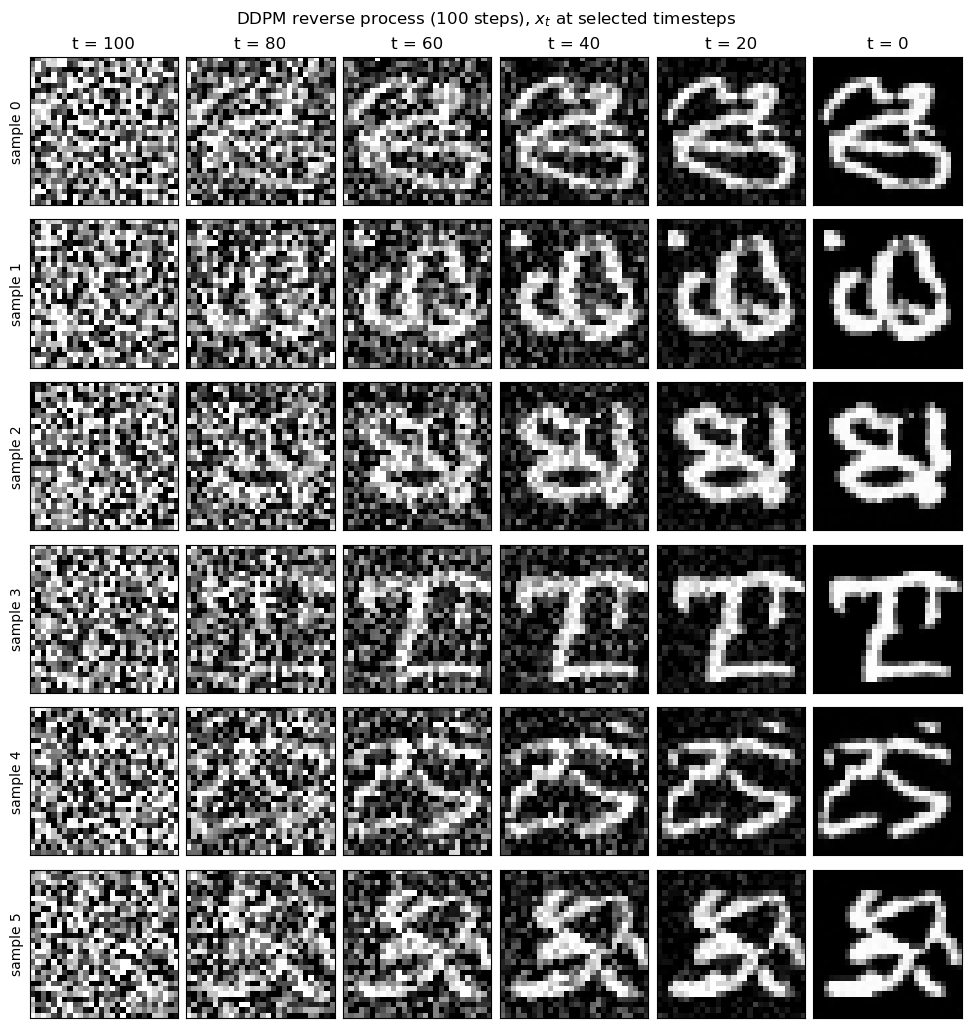

In [18]:
n_show = min(6, N_SAMPLES)
fig, axes = plt.subplots(n_show, len(TRAJ_STEPS), figsize=(1.6 * len(TRAJ_STEPS), 1.7 * n_show))
for r in range(n_show):
    for c, t in enumerate(TRAJ_STEPS):
        ax = axes[r, c]
        ax.imshow(denorm(ddpm_traj[t][r, 0]), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(f"t = {t}")
        if c == 0:
            ax.set_ylabel(f"sample {r}")
plt.suptitle(f"DDPM reverse process ({DDPM_STEPS} steps), " + r"$x_t$ at selected timesteps")
plt.savefig("figures/ddpm_reverse_process.png", dpi=150)
plt.show()

## 11. DDIM Sampling

DDIM (Song et al., 2021) uses **the same trained model**. Training is unchanged; only the sampling loop is different.

**Idea.** DDPM training only ever uses the closed-form marginals q(x_t | x_0) from Section 6. DDIM defines a different (non-Markovian) reverse process that has exactly the same marginals, so the trained ε_θ is still valid for it, but each step is allowed to jump between any two timesteps t → s with s < t. Each step does two things:

1. **Predict the clean image** with the noise prediction (the `recover_x0_from_noise` formula):
$$\hat{x}_0 = \frac{x_t - \sqrt{1 - \bar{\alpha}_t}\, \epsilon_\theta(x_t, t)}{\sqrt{\bar{\alpha}_t}}$$
2. **Re-noise it to the earlier level s**, reusing the predicted noise direction:
$$x_s = \sqrt{\bar{\alpha}_s}\, \hat{x}_0 + \sqrt{1 - \bar{\alpha}_s - \sigma_t^2}\; \epsilon_\theta(x_t, t) + \sigma_t z$$

**The role of η.** The amount of fresh noise is
$$\sigma_t = \eta \sqrt{\frac{1 - \bar{\alpha}_s}{1 - \bar{\alpha}_t}} \sqrt{1 - \frac{\bar{\alpha}_t}{\bar{\alpha}_s}}$$
With **η = 0** (used here), σ_t = 0, no random noise is added, and the sampler is a deterministic function of x_T: the same starting noise always gives the same image. With η = 1 and every step used, it becomes a stochastic DDPM-style sampler again (with the posterior variance instead of β_t).

**Reduced timestep schedule.** I use evenly spaced timesteps from T down to 0:

- 50 steps: 100, 98, 96, ..., 2, 0
- 20 steps: 100, 95, 90, ..., 5, 0

Every step uses ᾱ at both ends (`alpha_bars_full[t]` and `alpha_bars_full[s]`) and the model is called with `t_idx = t - 1`. The last step goes to s = 0, where ᾱ_0 = 1, so the output is just x̂_0.

**Why fewer steps work.** DDPM's update uses the single-step β_t and adds new noise each step, so it has to visit every t. DDIM's update only needs ᾱ_t and ᾱ_s, which are known in closed form for any pair, so steps can be skipped. With η = 0 the path from x_T to x_0 is smooth, so taking larger steps along it is a reasonable approximation. Each DDIM step still costs one network call, so 50 steps take about half the time of DDPM and 20 steps about a fifth.

In [19]:
def ddim_timesteps(num_steps):
    # evenly spaced timesteps from T down to 0, e.g. 20 steps -> [100, 95, ..., 5, 0]
    return np.linspace(T, 0, num_steps + 1).round().astype(int).tolist()


@torch.no_grad()
def ddim_sample(model, x_T, num_steps, eta=0.0, generator=None, save_at=()):
    '''
    DDIM sampling with num_steps jumps from t = T down to 0.
    eta = 0 gives deterministic sampling (generator is not needed then).
    '''
    model.eval()
    steps = ddim_timesteps(num_steps)
    x = x_T.clone()
    traj = {T: x.cpu()} if T in save_at else {}
    for t, s in zip(steps[:-1], steps[1:]):              # jump from t to s < t
        ab_t, ab_s = alpha_bars_full[t], alpha_bars_full[s]
        t_batch = torch.full((x.size(0),), t - 1, device=device, dtype=torch.long)
        eps_hat = model(x, t_batch)

        x0_hat = (x - torch.sqrt(1 - ab_t) * eps_hat) / torch.sqrt(ab_t)          # predicted clean image
        sigma = eta * torch.sqrt((1 - ab_s) / (1 - ab_t) * (1 - ab_t / ab_s))
        x = torch.sqrt(ab_s) * x0_hat + torch.sqrt(1 - ab_s - sigma ** 2) * eps_hat  # direction to x_t
        if eta > 0 and s > 0:
            x = x + sigma * torch.randn(x.shape, generator=generator).to(device)
        if s in save_at:
            traj[s] = x.cpu()
    return x, traj


for n in DDIM_STEPS:
    sched = ddim_timesteps(n)
    assert len(sched) == n + 1 and sched[0] == T and sched[-1] == 0
    assert all(a > b for a, b in zip(sched[:-1], sched[1:]))   # strictly decreasing, no repeated t
    log(f"DDIM {n} steps schedule: {sched[:4]} ... {sched[-4:]} ({n} model calls)")

[2026-10-27T20:56:10Z] DDIM 50 steps schedule: [100, 98, 96, 94] ... [6, 4, 2, 0] (50 model calls)
[2026-10-27T20:56:10Z] DDIM 20 steps schedule: [100, 95, 90, 85] ... [15, 10, 5, 0] (20 model calls)


Now sample with 50 and 20 steps, η = 0, from the same x_T as DDPM. Both samplers are timed the same way as DDPM.

[2026-10-27T20:56:11Z] DDIM 50 steps (eta=0.0): 64 images in 1.78s | output range [-1.04, 1.18]


[2026-10-27T20:56:12Z] DDIM 20 steps (eta=0.0): 64 images in 0.70s | output range [-1.05, 1.20]


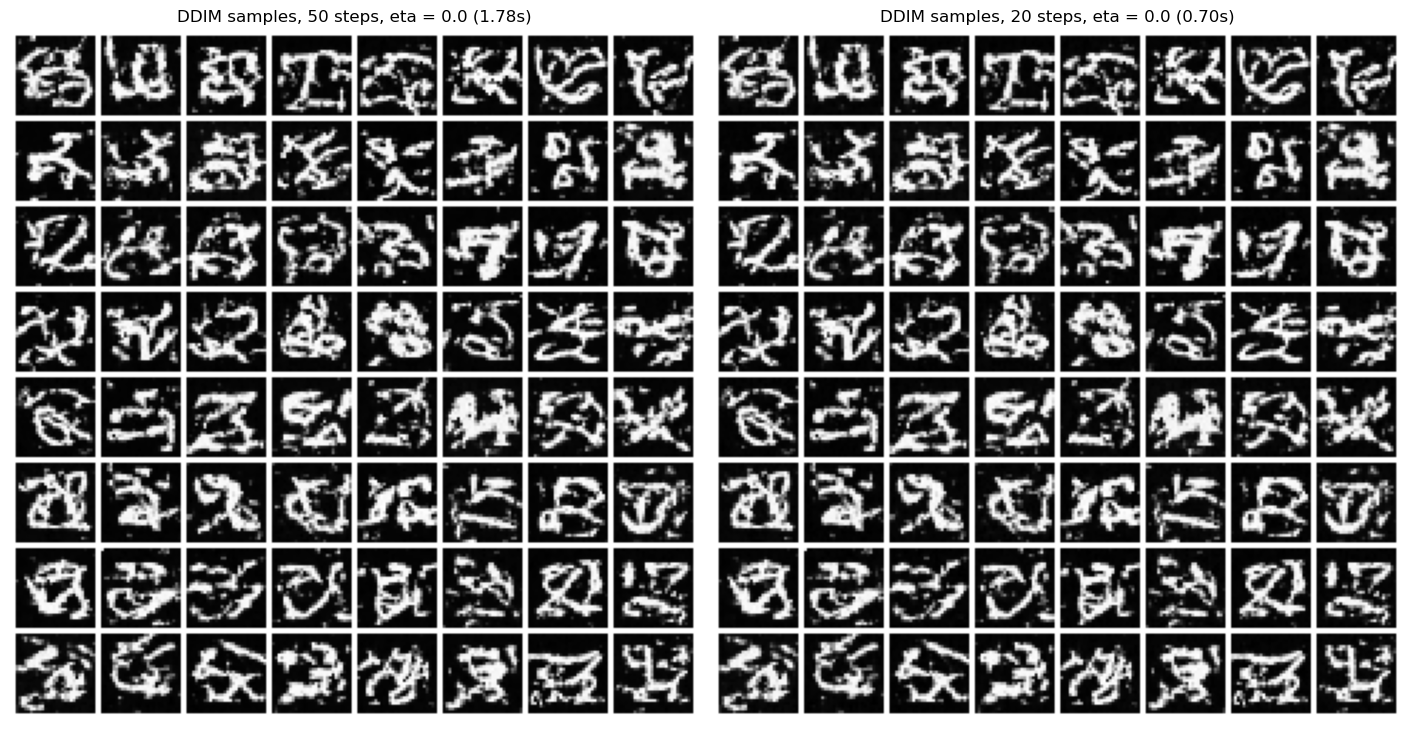

In [20]:
ddim_imgs, ddim_traj, ddim_time = {}, {}, {}
for n in DDIM_STEPS:
    sync(); t0 = time.time()
    ddim_imgs[n], ddim_traj[n] = ddim_sample(model, x_T, num_steps=n, eta=DDIM_ETA, save_at=TRAJ_STEPS)
    sync(); ddim_time[n] = time.time() - t0
    assert ddim_imgs[n].shape == x_T.shape and torch.isfinite(ddim_imgs[n]).all()
    log(f"DDIM {n} steps (eta={DDIM_ETA}): {N_SAMPLES} images in {ddim_time[n]:.2f}s | output range [{ddim_imgs[n].min().item():.2f}, {ddim_imgs[n].max().item():.2f}]")

fig, axes = plt.subplots(1, len(DDIM_STEPS), figsize=(7 * len(DDIM_STEPS), 7.4))
for ax, n in zip(axes, DDIM_STEPS):
    show_grid(ax, ddim_imgs[n], nrow=nrow, title=f"DDIM samples, {n} steps, eta = {DDIM_ETA} ({ddim_time[n]:.2f}s)")
plt.savefig("figures/ddim_samples.png", dpi=150)
plt.show()

**Stochasticity check.** DDIM with η = 0 should give exactly the same images when run again from the same x_T. DDPM run again from the same x_T but with a different noise seed should give different images.

[2026-10-27T20:56:17Z] DDIM 20 steps run twice from the same x_T: max |difference| = 0.00e+00
[2026-10-27T20:56:17Z] DDPM run twice from the same x_T (noise seeds 9487 vs 9488): mean |pixel difference| = 0.1450 (pixels in [0, 1])


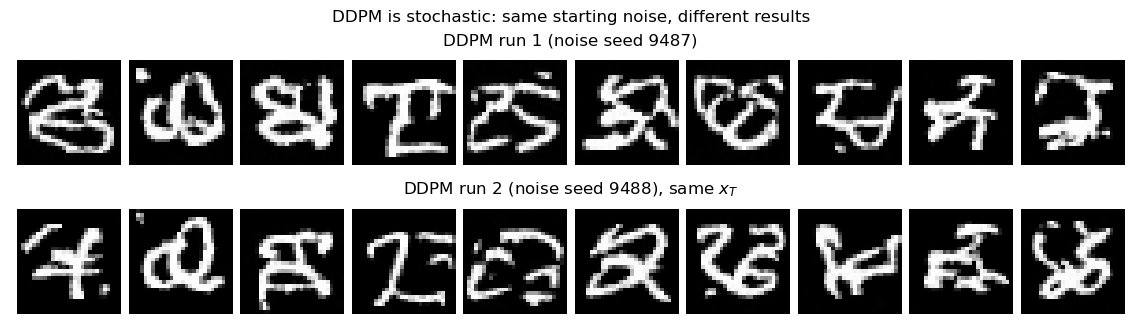

In [21]:
ddim_again, _ = ddim_sample(model, x_T, num_steps=DDIM_STEPS[-1], eta=DDIM_ETA)
ddim_repeat_diff = (ddim_again - ddim_imgs[DDIM_STEPS[-1]]).abs().max().item()

ddpm_again, _ = ddpm_sample(model, x_T, generator=make_generator(SEED + 2))
ddpm_repeat_diff = (denorm(ddpm_again) - denorm(ddpm_imgs)).abs().mean().item()

log(f"DDIM {DDIM_STEPS[-1]} steps run twice from the same x_T: max |difference| = {ddim_repeat_diff:.2e}")
log(f"DDPM run twice from the same x_T (noise seeds {SEED + 1} vs {SEED + 2}): mean |pixel difference| = {ddpm_repeat_diff:.4f} (pixels in [0, 1])")
assert ddim_repeat_diff < 1e-5

n_show = min(10, N_SAMPLES)
fig, axes = plt.subplots(2, 1, figsize=(12, 3.2))
show_grid(axes[0], ddpm_imgs[:n_show], nrow=n_show, title=f"DDPM run 1 (noise seed {SEED + 1})")
show_grid(axes[1], ddpm_again[:n_show], nrow=n_show, title=f"DDPM run 2 (noise seed {SEED + 2}), same " + r"$x_T$")
plt.suptitle("DDPM is stochastic: same starting noise, different results")
plt.savefig("figures/ddpm_two_runs.png", dpi=150)
plt.show()

## 12. DDPM versus DDIM Comparison

All three samplers start from the same 64 noise images x_T. The first figure shows the full grids side by side, and the second puts the first 10 samples of each method in rows, so each column is one starting noise image.

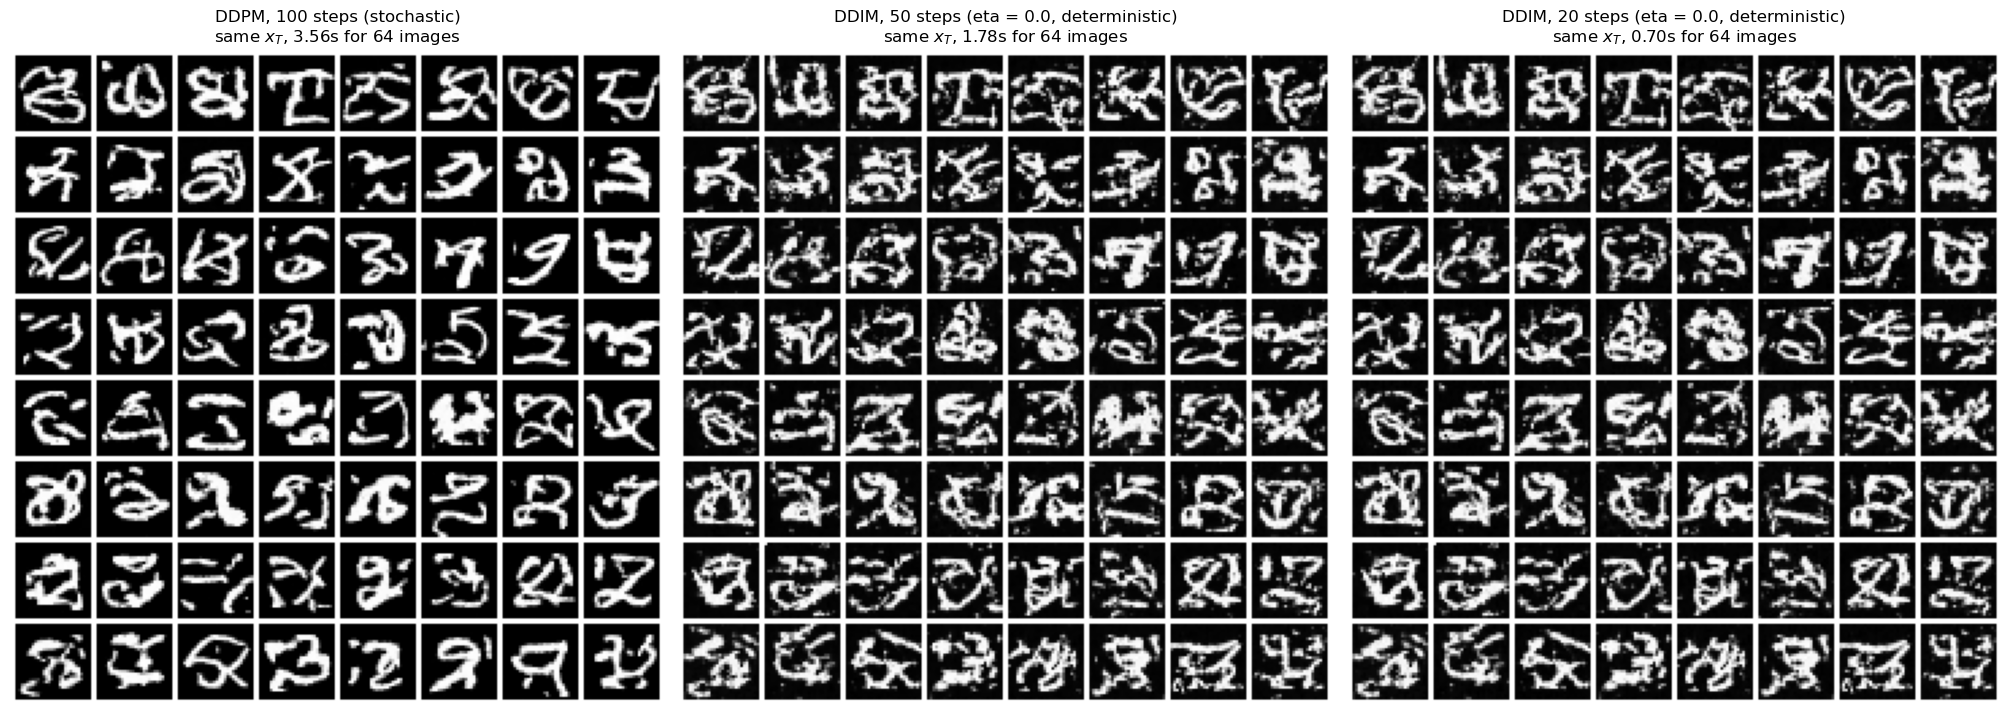

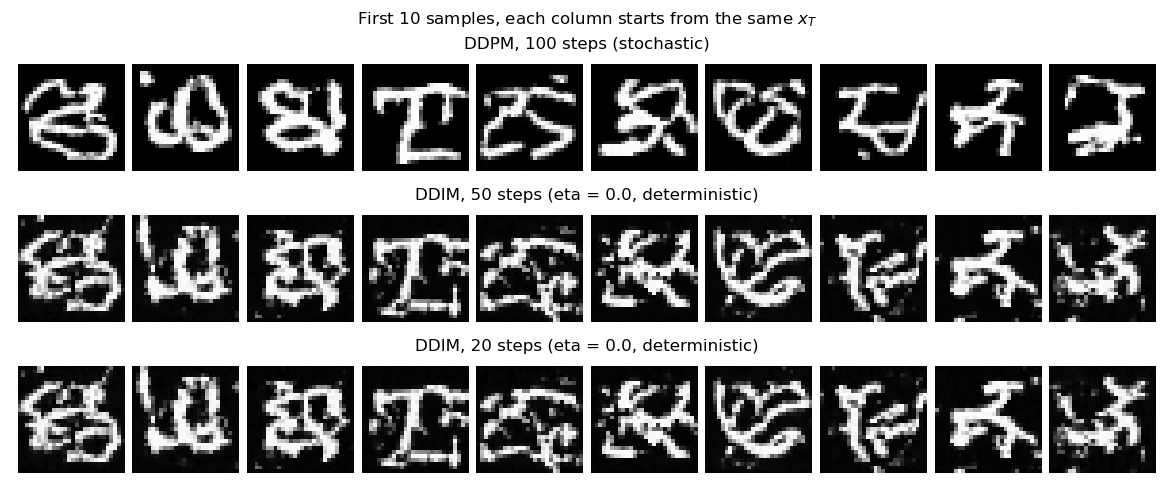

In [22]:
methods = [(f"DDPM, {DDPM_STEPS} steps (stochastic)", ddpm_imgs, ddpm_time)]
methods += [(f"DDIM, {n} steps (eta = {DDIM_ETA}, deterministic)", ddim_imgs[n], ddim_time[n]) for n in DDIM_STEPS]

fig, axes = plt.subplots(1, 3, figsize=(20, 7.4))
for ax, (name, imgs, sec) in zip(axes, methods):
    show_grid(ax, imgs, nrow=nrow, title=f"{name}\nsame " + r"$x_T$" + f", {sec:.2f}s for {N_SAMPLES} images")
plt.savefig("figures/ddpm_vs_ddim_grids.png", dpi=150)
plt.show()

n_show = min(10, N_SAMPLES)
fig, axes = plt.subplots(3, 1, figsize=(12, 4.8))
for ax, (name, imgs, _) in zip(axes, methods):
    show_grid(ax, imgs[:n_show], nrow=n_show, title=name)
plt.suptitle(f"First {n_show} samples, each column starts from the same " + r"$x_T$")
plt.savefig("figures/ddpm_vs_ddim_same_noise.png", dpi=150)
plt.show()

The reverse path of sample 0 under each sampler (DDIM 50 and 20 both pass through t = 100, 80, ..., 0, so the same timesteps can be shown for all three):

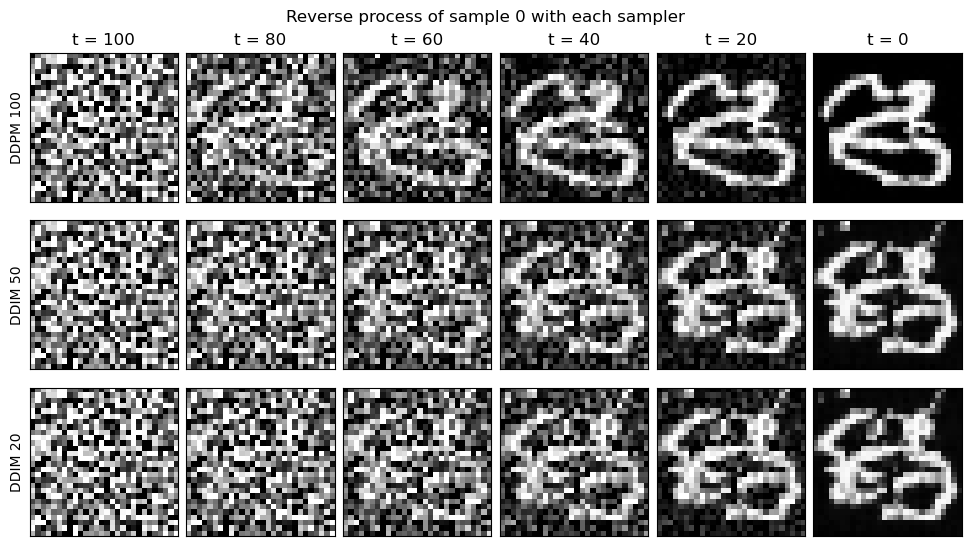

In [23]:
trajs = [(f"DDPM {DDPM_STEPS}", ddpm_traj)] + [(f"DDIM {n}", ddim_traj[n]) for n in DDIM_STEPS]
fig, axes = plt.subplots(len(trajs), len(TRAJ_STEPS), figsize=(1.6 * len(TRAJ_STEPS), 1.8 * len(trajs)))
for r, (name, traj) in enumerate(trajs):
    for c, t in enumerate(TRAJ_STEPS):
        ax = axes[r, c]
        ax.imshow(denorm(traj[t][0, 0]), cmap="gray", vmin=0, vmax=1)
        ax.set_xticks([]); ax.set_yticks([])
        if r == 0:
            ax.set_title(f"t = {t}")
        if c == 0:
            ax.set_ylabel(name)
plt.suptitle("Reverse process of sample 0 with each sampler")
plt.savefig("figures/reverse_paths_sample0.png", dpi=150)
plt.show()

**Numbers.** There is no standard image-quality metric here (FID would need a pretrained Inception network, which I did not want to download), so the table below only uses simple checks that are easy to compute and interpret:

- **steps / time:** network calls and wall-clock time for all samples.
- **mean pixel, ink fraction:** mean brightness and fraction of pixels above 0.5 (on the [0, 1] scale), compared with 1,000 real MNIST test images. Samples that are too noisy or too faint would move these away from the real values.
- **gray fraction:** fraction of pixels between 0.1 and 0.9. Real MNIST digits are mostly pure black background and white strokes, so speckle noise or blur raises this number.
- **diff vs DDPM:** mean absolute pixel difference from the DDPM image that started from the same x_T.

In [24]:
def pixel_stats(x):
    x01 = denorm(x.detach().cpu())
    return {
        "mean_pixel": x01.mean().item(),
        "ink_fraction": (x01 > 0.5).float().mean().item(),
        "gray_fraction": ((x01 > 0.1) & (x01 < 0.9)).float().mean().item(),
    }


real_stats = pixel_stats(test_data[:1000][0])
rows = [{"method": "Real MNIST (1,000 test images)", "steps": "-", "time_s": None, **real_stats, "diff_vs_ddpm": None}]
rows.append({"method": f"DDPM {DDPM_STEPS} steps", "steps": DDPM_STEPS, "time_s": ddpm_time, **pixel_stats(ddpm_imgs), "diff_vs_ddpm": 0.0})
for n in DDIM_STEPS:
    diff = (denorm(ddim_imgs[n]) - denorm(ddpm_imgs)).abs().mean().item()
    rows.append({"method": f"DDIM {n} steps (eta={DDIM_ETA})", "steps": n, "time_s": ddim_time[n], **pixel_stats(ddim_imgs[n]), "diff_vs_ddpm": diff})
ddim_50_vs_20 = (denorm(ddim_imgs[DDIM_STEPS[0]]) - denorm(ddim_imgs[DDIM_STEPS[1]])).abs().mean().item()

header = f"{'method':<32} {'steps':>5} {'time (s)':>9} {'ms/image':>9} {'mean pixel':>11} {'ink frac':>9} {'gray frac':>10} {'diff vs DDPM':>13}"
print(header)
print("-" * len(header))
for r in rows:
    t_s = f"{r['time_s']:.2f}" if r["time_s"] is not None else "-"
    ms = f"{1000 * r['time_s'] / N_SAMPLES:.1f}" if r["time_s"] is not None else "-"
    d = f"{r['diff_vs_ddpm']:.4f}" if r["diff_vs_ddpm"] is not None else "-"
    print(f"{r['method']:<32} {str(r['steps']):>5} {t_s:>9} {ms:>9} {r['mean_pixel']:>11.4f} {r['ink_fraction']:>9.4f} {r['gray_fraction']:>10.4f} {d:>13}")
print(f"\nmean |DDIM {DDIM_STEPS[0]} - DDIM {DDIM_STEPS[1]}| (same x_T): {ddim_50_vs_20:.4f}")
print(f"speed-up vs DDPM: " + ", ".join(f"DDIM {n}: {ddpm_time / ddim_time[n]:.2f}x" for n in DDIM_STEPS))
for r in rows:
    log("comparison:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in r.items()})
log(f"mean |DDIM {DDIM_STEPS[0]} - DDIM {DDIM_STEPS[1]}| = {ddim_50_vs_20:.4f}")

method                           steps  time (s)  ms/image  mean pixel  ink frac  gray frac  diff vs DDPM
---------------------------------------------------------------------------------------------------------
Real MNIST (1,000 test images)       -         -         -      0.1223    0.1239     0.0850             -
DDPM 100 steps                     100      3.56      55.7      0.2167    0.2181     0.1596        0.0000
DDIM 50 steps (eta=0.0)             50      1.78      27.9      0.2604    0.2463     0.2493        0.1407
DDIM 20 steps (eta=0.0)             20      0.70      11.0      0.2595    0.2445     0.2531        0.1402

mean |DDIM 50 - DDIM 20| (same x_T): 0.0046
speed-up vs DDPM: DDIM 50: 2.00x, DDIM 20: 5.08x
[2026-10-27T20:56:20Z] comparison: {'method': 'Real MNIST (1,000 test images)', 'steps': '-', 'time_s': None, 'mean_pixel': 0.1223, 'ink_fraction': 0.1239, 'gray_fraction': 0.085, 'diff_vs_ddpm': None}
[2026-10-27T20:56:20Z] comparison: {'method': 'DDPM 100 steps', 'ste

### Diagnostic: is the model the problem, or the starting noise?

Section 5 showed that with this schedule ᾱ_100 ≈ 0.36, so during training x_100 always still contained 0.60·x_0. At sampling time the reverse process starts from pure N(0, I) instead, which the model never saw at t = 100. To separate "the model or sampler code is wrong" from "the starting point does not match training", this cell runs the same samplers from two kinds of x_100:

1. **x_100 from the real forward process**, q(x_100 | x_0), using 16 test images (never used for training). If the model and samplers are correct, both DDPM and DDIM should bring these back to clean digits close to the originals. This is not generation (the digit is still partly in x_100), it is only a correctness check.
2. **x_100 = pure noise** (the first 16 x_T from above), with DDIM 20 steps and **η = 1**. This shows whether adding fresh noise during DDIM (like DDPM does) changes how the samples look.

[2026-10-27T20:56:21Z] diagnostic: DDPM 100 from real x_100: mean |output - x0| = 0.0399
[2026-10-27T20:56:21Z] diagnostic: DDIM 20 (eta=0) from real x_100: mean |output - x0| = 0.0313
[2026-10-27T20:56:21Z] diagnostic: DDIM 20 (eta=1) from pure noise: {'mean_pixel': 0.2144, 'ink_fraction': 0.2157, 'gray_fraction': 0.1636}


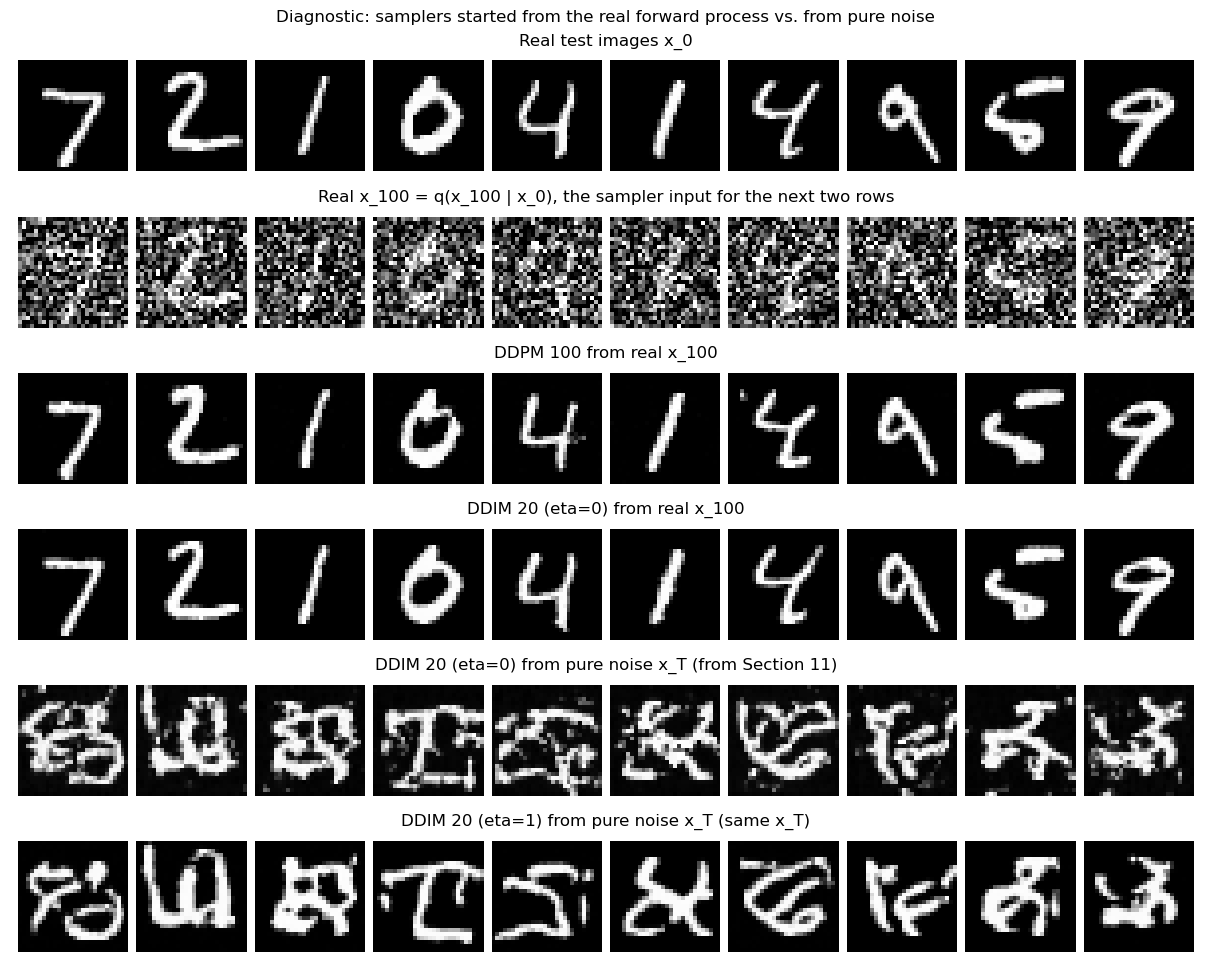

In [25]:
n_diag = min(16, N_SAMPLES)
x0_diag = test_data[:n_diag][0].to(device)
eps_diag = torch.randn(x0_diag.shape, generator=make_generator(SEED)).to(device)
xT_real, _ = q_sample(x0_diag, torch.full((n_diag,), T - 1, device=device), eps_diag)

diag = {
    "DDPM 100 from real x_100": ddpm_sample(model, xT_real, generator=make_generator(SEED + 1))[0],
    "DDIM 20 (eta=0) from real x_100": ddim_sample(model, xT_real, num_steps=20)[0],
    "DDIM 20 (eta=1) from pure noise x_T": ddim_sample(model, x_T[:n_diag], num_steps=20, eta=1.0, generator=make_generator(SEED + 3))[0],
}
diag_err = {k: (denorm(v) - denorm(x0_diag)).abs().mean().item() for k, v in diag.items() if "real" in k}
for k, v in diag_err.items():
    log(f"diagnostic: {k}: mean |output - x0| = {v:.4f}")
diag_eta1_stats = pixel_stats(diag["DDIM 20 (eta=1) from pure noise x_T"])
log("diagnostic: DDIM 20 (eta=1) from pure noise:", {k: round(v, 4) for k, v in diag_eta1_stats.items()})

n_show = min(10, n_diag)
panels = [("Real test images x_0", x0_diag), ("Real x_100 = q(x_100 | x_0), the sampler input for the next two rows", xT_real)]
panels += [(k, diag[k]) for k in ["DDPM 100 from real x_100", "DDIM 20 (eta=0) from real x_100"]]
panels += [(f"DDIM {DDIM_STEPS[-1]} (eta=0) from pure noise x_T (from Section 11)", ddim_imgs[DDIM_STEPS[-1]])]
panels += [("DDIM 20 (eta=1) from pure noise x_T (same x_T)", diag["DDIM 20 (eta=1) from pure noise x_T"])]
fig, axes = plt.subplots(len(panels), 1, figsize=(12, 1.6 * len(panels)))
for ax, (name, imgs) in zip(axes, panels):
    show_grid(ax, imgs[:n_show], nrow=n_show, title=name)
plt.suptitle("Diagnostic: samplers started from the real forward process vs. from pure noise")
plt.savefig("figures/diagnostic_start_noise.png", dpi=150)
plt.show()

Save the settings, losses, and comparison numbers to `results/hw8_metrics.json` (used for METRICS.md).

In [26]:
metrics = {
    "personal_parameters": {"SID4": SID4, "SEED": SEED, "SLICE": SLICE, "HP_ID": HP_ID, "CLS_A": CLS_A, "CLS_B": CLS_B},
    "smoke_test": SMOKE_TEST,
    "device": device,
    "device_name": device_name,
    "versions": {"torch": torch.__version__, "torchvision": torchvision.__version__, "numpy": np.__version__},
    "settings": {"T": T, "beta_start": BETA_START, "beta_end": BETA_END, "batch_size": BATCH_SIZE, "epochs": EPOCHS,
                 "lr": LR, "base_ch": BASE_CH, "time_dim": TIME_DIM, "train_images": len(train_data),
                 "n_samples": N_SAMPLES, "ddim_steps": DDIM_STEPS, "ddim_eta": DDIM_ETA},
    "schedule": {f"alpha_bar_{t}": alpha_bars_full[t].item() for t in FWD_TIMESTEPS},
    "forward_image_test_index": FWD_IDX,
    "model": {"parameters": n_params, "conv_layers": n_conv},
    "training": {"epoch_losses": epoch_losses, "first_step_loss": step_losses[0], "train_time_s": train_time,
                 "test_mse_before": test_mse_before, "test_mse_after": test_mse_after},
    "sampling": {"ddpm_time_s": ddpm_time, "ddim_time_s": {str(n): ddim_time[n] for n in DDIM_STEPS},
                 "ddim_repeat_max_diff": ddim_repeat_diff, "ddpm_repeat_mean_diff": ddpm_repeat_diff,
                 "ddim_50_vs_20_mean_diff": ddim_50_vs_20, "table": rows},
    "diagnostic": {"mean_abs_error_from_real_x100": diag_err, "ddim20_eta1_from_pure_noise": diag_eta1_stats},
}
with open("results/hw8_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)
log("saved results/hw8_metrics.json and", f"checkpoints/mini_ddpm_seed_{SEED}.pt")

[2026-10-27T20:56:22Z] saved results/hw8_metrics.json and checkpoints/mini_ddpm_seed_9486.pt


## 13. Discussion and Conclusion

All numbers below come from the run saved in `results/run_log_raw.txt` and `results/hw8_metrics.json` (Apple MPS, seed 9486, 50 epochs). This cell was written after the run finished, and the notebook was not re-run after adding it.

**Forward diffusion.** The forward process mixes the clean image with Gaussian noise using $x_t = \sqrt{\bar\alpha_t}\,x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon$. In the Section 6 figure the digit 6 is easy to read at t = 10 and t = 30, starts to break up at t = 60, and is mostly gone at t = 100. The check on 1,000 test images matched the formula closely: at t = 100 the measured mean was -0.4571 (formula -0.4555) and the std was 0.8741 (formula 0.8752). Recovering $x_0$ from $x_t$ with the true noise gave an error of only 1.19e-07, so the closed-form sampler is implemented correctly.

**Role of the beta schedule.** The betas control how much noise is added at each step. With the assigned linear schedule (0.0001 to 0.02, T = 100), $\bar\alpha_{100} = 0.364$, so $\sqrt{\bar\alpha_{100}} = 0.603$ and a faint trace of the digit is still in $x_{100}$. That means $x_T$ is **not** really $\mathcal{N}(0, I)$ in this setup, while sampling starts from pure $\mathcal{N}(0, I)$. This mismatch turned out to explain most of what I saw in the samples (see the diagnostic below).

**Timestep conditioning.** The model gets t through a sinusoidal embedding and a small MLP, and each block adds a per-channel shift from that embedding. This matters because the same noisy image needs a different correction near t = 100 than near t = 1. Even before training, changing t from 1 to 100 changed the output by 0.0416 on average, so the time signal is actually reaching the network.

**Training.** The noise-prediction loss went from 0.12903 in epoch 1 to 0.05244 in epoch 50 (lowest 0.05219 at epoch 46). Test MSE went from 1.28678 before training to 0.05245 after. Most of the drop happened in the first five epochs; after that it only slowly improved. Training took about 97 minutes on MPS.

**DDPM reverse process.** DDPM goes back through all 100 steps. At each step it removes the predicted noise and then adds fresh noise with variance $\beta_t$ (except at the last step). In the reverse-process figure the noise stays random until about t = 80, the stroke layout appears around t = 60, and t = 40 to t = 0 mostly sharpens it. The final DDPM samples have smooth, thick, MNIST-like strokes on a clean black background. Only a few of them look like real digits, though; many are digit-like scribbles.

**How DDIM changes sampling.** At each step DDIM first estimates the clean image, $\hat x_0 = (x_t - \sqrt{1-\bar\alpha_t}\,\hat\epsilon)/\sqrt{\bar\alpha_t}$. It then jumps straight to an earlier timestep $s$ with $x_s = \sqrt{\bar\alpha_s}\,\hat x_0 + \sqrt{1-\bar\alpha_s-\sigma^2}\,\hat\epsilon + \sigma z$. Because this jump follows the same marginals $q(x_t \mid x_0)$ the model was trained on, it can skip timesteps: 50 steps use t = 100, 98, ..., 0, and 20 steps use t = 100, 95, ..., 0. With $\eta = 0$ we have $\sigma = 0$, so the whole path is deterministic.

**What I observed when comparing them:**

| | DDPM 100 | DDIM 50 | DDIM 20 |
|---|---|---|---|
| Time for 64 images | 3.56 s | 1.78 s (2.0x faster) | 0.70 s (5.1x faster) |
| Ink fraction (real MNIST 0.124) | 0.218 | 0.246 | 0.245 |
| Gray fraction (real MNIST 0.085) | 0.160 | 0.249 | 0.253 |
| Same $x_T$ twice | different (mean diff 0.1450) | identical | identical (max diff 0.0) |

- **Speed:** DDIM time scales with the number of model calls, as expected.
- **Fewer steps:** DDIM 50 and DDIM 20 are almost the same images (mean difference 0.0046), so in this model cutting from 50 to 20 steps lost basically nothing.
- **Stochasticity:** DDIM with $\eta = 0$ gives exactly the same output when run twice. DDPM gives a visibly different image for the same $x_T$ because of the fresh noise at every step.
- **Quality:** DDIM samples follow roughly the same layout as the DDPM samples from the same $x_T$, but they look worse: speckled, with more gray pixels and messier strokes. In the reverse-path figure the DDIM paths also stay noisy for longer, and structure only shows up around t = 40.

**Diagnostic: why DDIM looked worse here.** When I started the samplers from a *real* $x_{100}$ (made by the forward process), both recovered the original digits: mean error 0.0399 for DDPM and 0.0313 for DDIM-20. So the trained model and both samplers work. The problem is the start: pure $\mathcal{N}(0,I)$ noise does not look like a real $x_{100}$ under this schedule. DDPM keeps adding fresh noise, which seems to help it correct for that. DDIM with $\eta = 0$ is deterministic, so it carries the bad start all the way through. Running DDIM-20 with $\eta = 1$ from the same pure noise gave smooth samples again (gray fraction 0.164, close to DDPM's 0.160), which supports this explanation.

**Limitations.**
- One run with one seed (9486) on MPS.
- Quality is judged only by looking at the grids and by simple pixel statistics (ink and gray fraction), not FID or a digit classifier.
- The assigned schedule leaves $\bar\alpha_T = 0.36$, which limits sample quality from pure noise. A schedule that ends near $\bar\alpha_T \approx 0$ (larger final beta, more steps, or a cosine schedule) would probably help most, especially for DDIM.
- The model is small (710,593 parameters) and unconditional, so it cannot be asked for a specific digit.

**Conclusion.** The full pipeline worked: forward diffusion, a time-conditioned noise predictor, DDPM sampling, and DDIM sampling with 50 and 20 steps. DDIM was 2 to 5 times faster and fully deterministic, and going from 50 to 20 steps barely changed the output. DDPM gave cleaner-looking samples in this setup. The diagnostic suggests the reason is the short linear schedule, not a bug in the model or the samplers.